

# 🌫️ SmogNet — Air Quality Intelligence Pipeline
### Pakistan Air Quality Datathon

**Pipeline stages:**
1. Data Loading (local folders, CSV + XLSX)
2. Data Cleaning & Schema Alignment
3. Feature Engineering (leak-safe, per-city)
4. Anomaly Detection (IsolationForest + Z-score)
5. Source Classification (LightGBM / RandomForest)
6. Final Predictions & Output

> **Run all cells top to bottom. No manual steps required after setting folder paths in Cell 1.**

## ⚙️ Cell 1 — Install Dependencies

In [1]:
import subprocess, sys

def _pip(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

for pkg in ["lightgbm", "openpyxl", "pyarrow"]:
    try:
        __import__(pkg.replace("-", "_"))
    except ImportError:
        print(f"Installing {pkg}...")
        _pip(pkg)

print("✅ Dependencies ready")

Installing lightgbm...
✅ Dependencies ready


## 📁 Cell 2 — Configuration: Set Your Folder Paths Here

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
from scipy import stats

try:
    import lightgbm as lgb
    LGBM_AVAILABLE = True
    print("✅ LightGBM available")
except ImportError:
    LGBM_AVAILABLE = False
    print("ℹ  LightGBM not found — will use RandomForest")

# ── ✏️  SET YOUR PATHS HERE ──────────────────────────────────────────────────
TRAIN_FOLDER = Path(r"C:\Users\Ameeni\Desktop\Progress 2\archive (1)\Training")
TEST_FOLDER  = Path(r"C:\Users\Ameeni\Desktop\Progress 2\archive (1)\Testing")
OUTPUT_DIR   = Path(".")          # outputs saved to same directory as notebook
# ─────────────────────────────────────────────────────────────────────────────

assert TRAIN_FOLDER.exists(), f"❌ Train folder not found: {TRAIN_FOLDER}"
assert TEST_FOLDER.exists(),  f"❌ Test folder not found: {TEST_FOLDER}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Global constants ──────────────────────────────────────────────────────────
RANDOM_STATE   = 42
ANOMALY_CONTAM = 0.05      # 5 % contamination for IsolationForest
ZSCORE_THRESH  = 3.0

POLLUTANT_COLS = ["co", "no", "no2", "so2", "o3", "pm2_5", "pm10", "nh3", "aqi"]
WEATHER_COLS   = ["temperature", "humidity"]
NUMERIC_COLS   = POLLUTANT_COLS + WEATHER_COLS

# Canonical column aliases (key = lowercase stripped form → canonical name)
COLUMN_ALIASES = {
    "date":             "datetime",
    "time":             "datetime",
    "date_time":        "datetime",
    "timestamp":        "datetime",
    "datetime":         "datetime",
    "city":             "city",
    "station":          "city",
    "location":         "city",
    "aqi":              "aqi",
    "air_quality_index":"aqi",
    "co":               "co",
    "no":               "no",
    "no2":              "no2",
    "so2":              "so2",
    "o3":               "o3",
    "pm2_5":            "pm2_5",
    "pm2.5":            "pm2_5",
    "pm25":             "pm2_5",
    "pm_2_5":           "pm2_5",
    "pm10":             "pm10",
    "nh3":              "nh3",
    "temperature":      "temperature",
    "temp":             "temperature",
    "humidity":         "humidity",
    "rh":               "humidity",
    "relative_humidity":"humidity",
}

FILENAME_CITY_MAP = {
    "islamabad": "Islamabad",
    "karachi":   "Karachi",
    "lahore":    "Lahore",
    "peshawar":  "Peshawar",
    "quetta":    "Quetta",
}

SOURCE_LABELS = ["Crop Burning", "Vehicular", "Industrial", "Dust Storm", "Mixed"]

print("✅ Configuration loaded")
print(f"   Train folder : {TRAIN_FOLDER}")
print(f"   Test folder  : {TEST_FOLDER}")

✅ LightGBM available
✅ Configuration loaded
   Train folder : C:\Users\Ameeni\Desktop\Progress 2\archive (1)\Training
   Test folder  : C:\Users\Ameeni\Desktop\Progress 2\archive (1)\Testing


## 🗂️ Cell 3 — Data Loading Layer

In [3]:
def _standardise_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Lowercase + replace spaces/dots with underscores, then apply aliases."""
    df.columns = (
        df.columns
          .str.strip()
          .str.lower()
          .str.replace(r"[\s\.]+", "_", regex=True)
          .str.replace(r"[^a-z0-9_]", "", regex=True)
    )
    rename = {}
    for col in df.columns:
        if col in COLUMN_ALIASES and COLUMN_ALIASES[col] != col:
            rename[col] = COLUMN_ALIASES[col]
    if rename:
        df = df.rename(columns=rename)
    # De-duplicate column names (keep first)
    df = df.loc[:, ~df.columns.duplicated()]
    return df


def _infer_city(filename: str) -> str | None:
    lower = filename.lower()
    for kw, city in FILENAME_CITY_MAP.items():
        if kw in lower:
            return city
    return None


def _read_file(path: Path) -> pd.DataFrame:
    ext = path.suffix.lower()
    if ext == ".csv":
        df = pd.read_csv(path, low_memory=False)
    elif ext in (".xlsx", ".xls"):
        df = pd.read_excel(path)
    else:
        raise ValueError(f"Unsupported file type: {ext}")
    return df


def load_folder(folder: Path, label: str = "") -> pd.DataFrame:
    """Load every CSV / XLSX in *folder*, merge into one DataFrame."""
    files = sorted([p for p in folder.iterdir()
                    if p.suffix.lower() in (".csv", ".xlsx", ".xls")])
    if not files:
        raise FileNotFoundError(f"No CSV/XLSX files found in {folder}")

    frames = []
    for path in files:
        try:
            df = _read_file(path)
            df = _standardise_columns(df)

            # Inject city from filename when not present or all-null
            city_from_file = _infer_city(path.name)
            if city_from_file:
                if "city" not in df.columns or df["city"].isna().all():
                    df["city"] = city_from_file
                else:
                    # Normalise existing city values
                    df["city"] = df["city"].astype(str).str.strip().str.title()
            elif "city" not in df.columns:
                df["city"] = "Unknown"
            else:
                df["city"] = df["city"].astype(str).str.strip().str.title()

            frames.append(df)
            print(f"  ✔  {path.name:55s} → {df.shape[0]:>7,} rows, {df.shape[1]:>3} cols")
        except Exception as exc:
            print(f"  ⚠  Skipped {path.name}: {exc}")

    merged = pd.concat(frames, ignore_index=True)
    print(f"\n{'─'*60}")
    print(f"  {label} total : {merged.shape[0]:,} rows × {merged.shape[1]} cols")
    return merged


print("Loading TRAIN data...")
raw_train = load_folder(TRAIN_FOLDER, "TRAIN")

print("\nLoading TEST data...")
raw_test  = load_folder(TEST_FOLDER,  "TEST")

print("\n✅ Raw data loaded")

Loading TRAIN data...
  ✔  concatenated_dataset_Aug_2021_to_July_2024.csv          → 123,134 rows,  19 cols
  ✔  islamabad_complete_data.xlsx                            →  28,245 rows,  19 cols
  ✔  karachi_complete_data.xlsx                              →  28,221 rows,  19 cols
  ✔  lahore_complete_data.xlsx                               →  28,269 rows,  19 cols
  ✔  peshawar_complete_data.csv                              →  28,245 rows,  19 cols
  ✔  quetta_complete_data.csv                                →  28,221 rows,  19 cols

────────────────────────────────────────────────────────────
  TRAIN total : 264,335 rows × 19 cols

Loading TEST data...
  ✔  islamabad_complete_data_july_to_dec_2024.csv            →   4,368 rows,  19 cols
  ✔  karachi_complete_data_july_to_dec_2024.csv              →   4,344 rows,  19 cols
  ✔  lahore_complete_data_july_to_dec_2024.csv               →   4,368 rows,  19 cols
  ✔  peshawar_complete_data_july_to_dec_2024.csv             →   4,368 rows,  19 

## 🧹 Cell 4 — Data Cleaning Layer

In [4]:
def _parse_datetime(df: pd.DataFrame) -> pd.DataFrame:
    """Robustly parse the datetime column; drop rows that cannot be parsed."""
    if "datetime" not in df.columns:
        # Try to find any date-like column
        candidates = [c for c in df.columns if "date" in c or "time" in c]
        if candidates:
            df = df.rename(columns={candidates[0]: "datetime"})
        else:
            raise KeyError("No datetime column found in dataset")

    df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce", infer_datetime_format=True)
    n_bad = df["datetime"].isna().sum()
    if n_bad > 0:
        print(f"  ⚠  Dropped {n_bad:,} rows with unparseable datetime")
        df = df.dropna(subset=["datetime"])
    return df


def _ensure_numeric(df: pd.DataFrame) -> pd.DataFrame:
    """Coerce NUMERIC_COLS to float; missing cols are added as NaN."""
    for col in NUMERIC_COLS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
        else:
            df[col] = np.nan
    return df


def _clip_negatives(df: pd.DataFrame) -> pd.DataFrame:
    """Pollutant concentrations cannot be negative."""
    for col in POLLUTANT_COLS:
        if col in df.columns:
            df[col] = df[col].clip(lower=0)
    return df


def _dedup_sort(df: pd.DataFrame) -> pd.DataFrame:
    df = df.drop_duplicates(subset=["datetime", "city"])
    df = df.sort_values(["city", "datetime"]).reset_index(drop=True)
    return df


def clean_data(df: pd.DataFrame, label: str = "") -> pd.DataFrame:
    print(f"Cleaning {label}...")
    df = _parse_datetime(df)
    df = _ensure_numeric(df)
    df = _clip_negatives(df)
    df = _dedup_sort(df)

    # Round to nearest hour to align data from different sources
    df["datetime"] = df["datetime"].dt.floor("h")
    df = df.drop_duplicates(subset=["datetime", "city"]).reset_index(drop=True)

    # Report missingness
    miss = df[NUMERIC_COLS].isna().mean().sort_values(ascending=False)
    miss_report = miss[miss > 0]
    if len(miss_report):
        print(f"  Missing % (numeric cols):")
        for c, v in miss_report.items():
            print(f"    {c:20s}: {100*v:.1f}%")

    print(f"  → {df.shape[0]:,} rows after cleaning\n")
    return df


train_clean = clean_data(raw_train, "TRAIN")
test_clean  = clean_data(raw_test,  "TEST")

# ── Align schemas: test must have same columns as train ─────────────────────
shared_non_feat = ["datetime", "city"]
for col in NUMERIC_COLS:
    if col not in test_clean.columns:
        test_clean[col] = np.nan
    if col not in train_clean.columns:
        train_clean[col] = np.nan

print("✅ Data cleaning complete")
print(f"   Train : {train_clean.shape}")
print(f"   Test  : {test_clean.shape}")

Cleaning TRAIN...
  ⚠  Dropped 34,296 rows with unparseable datetime
  Missing % (numeric cols):
    co                  : 100.0%
    no                  : 100.0%
    no2                 : 100.0%
    so2                 : 100.0%
    o3                  : 100.0%
    pm2_5               : 100.0%
    pm10                : 100.0%
    nh3                 : 100.0%
    aqi                 : 100.0%
    temperature         : 100.0%
    humidity            : 100.0%
  → 131,551 rows after cleaning

Cleaning TEST...
  ⚠  Dropped 13,272 rows with unparseable datetime
  Missing % (numeric cols):
    co                  : 100.0%
    no                  : 100.0%
    no2                 : 100.0%
    so2                 : 100.0%
    o3                  : 100.0%
    pm2_5               : 100.0%
    pm10                : 100.0%
    nh3                 : 100.0%
    aqi                 : 100.0%
    temperature         : 100.0%
    humidity            : 100.0%
  → 8,520 rows after cleaning

✅ Data cleaning c

## 🔧 Cell 5 — Feature Engineering (Leak-Safe)

In [5]:
def _pakistan_season(month: pd.Series) -> pd.Series:
    """
    Pakistan seasons:
      Winter  : Dec, Jan, Feb
      Spring  : Mar, Apr
      Summer  : May, Jun
      Monsoon : Jul, Aug, Sep
      Autumn  : Oct, Nov
    """
    conditions = [
        month.isin([12, 1, 2]),
        month.isin([3, 4]),
        month.isin([5, 6]),
        month.isin([7, 8, 9]),
        month.isin([10, 11]),
    ]
    choices = ["Winter", "Spring", "Summer", "Monsoon", "Autumn"]
    return np.select(conditions, choices, default="Unknown")


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Build all features per-city to avoid leakage.
    Rolling / lag features use shift(1) so no row sees its own value.
    """
    df = df.copy()

    # ── 1. Temporal features ───────────────────────────────────────────────
    dt = df["datetime"]
    df["hour"]         = dt.dt.hour
    df["day_of_week"]  = dt.dt.dayofweek
    df["month"]        = dt.dt.month
    df["day_of_year"]  = dt.dt.dayofyear
    df["week_of_year"] = dt.dt.isocalendar().week.astype(int)
    df["is_weekend"]   = (df["day_of_week"] >= 5).astype(int)

    # Cyclic encoding
    df["hour_sin"]   = np.sin(2 * np.pi * df["hour"]   / 24)
    df["hour_cos"]   = np.cos(2 * np.pi * df["hour"]   / 24)
    df["month_sin"]  = np.sin(2 * np.pi * df["month"]  / 12)
    df["month_cos"]  = np.cos(2 * np.pi * df["month"]  / 12)
    df["dow_sin"]    = np.sin(2 * np.pi * df["day_of_week"] / 7)
    df["dow_cos"]    = np.cos(2 * np.pi * df["day_of_week"] / 7)

    # Pakistan season
    df["season"] = _pakistan_season(df["month"])
    df["season_code"] = df["season"].map(
        {"Winter": 0, "Spring": 1, "Summer": 2, "Monsoon": 3, "Autumn": 4}
    ).fillna(0).astype(int)

    # ── 2. Pollution ratio features ────────────────────────────────────────
    eps = 1e-6
    df["pm_ratio"]       = df["pm2_5"] / (df["pm10"] + eps)
    df["traffic_index"]  = df["no"].fillna(0) + df["no2"].fillna(0)
    df["crop_burn_signal"] = df["nh3"].fillna(0) + df["co"].fillna(0)

    # ── 3. Per-city lag & rolling (shift FIRST to prevent leakage) ─────────
    lag_hours   = [1, 6, 24]
    roll_windows = [3, 6, 24]

    groups = df.groupby("city", sort=False)

    lag_frames  = []
    roll_frames = []

    for col in POLLUTANT_COLS:
        if col not in df.columns:
            continue
        g = groups[col]

        # Lag features
        for h in lag_hours:
            lag_frames.append(
                g.shift(h).rename(f"{col}_lag{h}h")
            )

        # Rolling stats — shift(1) so window never includes current row
        shifted = g.shift(1)
        for w in roll_windows:
            lag_frames.append(
                shifted.transform(lambda x: x.rolling(w, min_periods=1).mean())
                       .rename(f"{col}_roll{w}h_mean")
            )
            lag_frames.append(
                shifted.transform(lambda x: x.rolling(w, min_periods=1).std())
                       .rename(f"{col}_roll{w}h_std")
            )

    # AQI delta per city
    if "aqi" in df.columns:
        lag_frames.append(
            (groups["aqi"].transform("mean") - df["aqi"]).rename("aqi_delta_city")
        )

    df = pd.concat([df] + lag_frames + roll_frames, axis=1)

    # ── 4. City label encoding ─────────────────────────────────────────────
    known_cities = sorted(FILENAME_CITY_MAP.values())
    city_map = {c: i for i, c in enumerate(known_cities)}
    df["city_code"] = df["city"].map(city_map).fillna(len(city_map)).astype(int)

    return df


print("Engineering features...")
train_feat = engineer_features(train_clean)
test_feat  = engineer_features(test_clean)

print(f"  Train feature matrix : {train_feat.shape}")
print(f"  Test  feature matrix : {test_feat.shape}")
print("✅ Feature engineering complete")

Engineering features...
  Train feature matrix : (131551, 130)
  Test  feature matrix : (8520, 130)
✅ Feature engineering complete


## 🔍 Cell 6 — Preprocessing: Impute & Scale

In [6]:
NON_FEATURE_COLS = {"datetime", "city", "season",
                    "anomaly_flag", "anomaly_score", "source_label"}

def _get_feature_cols(df: pd.DataFrame) -> list:
    return [c for c in df.columns
            if c not in NON_FEATURE_COLS
            and pd.api.types.is_numeric_dtype(df[c])]


# Build feature list from TRAIN only
FEATURE_COLS = _get_feature_cols(train_feat)
print(f"Feature columns ({len(FEATURE_COLS)}): {FEATURE_COLS[:10]} ...")

# ── Align test to train features (reindex — no manual injection) ───────────
for col in FEATURE_COLS:
    if col not in test_feat.columns:
        test_feat[col] = np.nan

X_train_raw = train_feat[FEATURE_COLS].values
X_test_raw  = test_feat[FEATURE_COLS].values

# ── Impute with median (fit on train only) ─────────────────────────────────
imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train_raw)
X_test_imp  = imputer.transform(X_test_raw)

# ── Scale with RobustScaler (fit on train only) ────────────────────────────
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled  = scaler.transform(X_test_imp)

print(f"\n  X_train_scaled : {X_train_scaled.shape}")
print(f"  X_test_scaled  : {X_test_scaled.shape}")
print("✅ Preprocessing complete (fit on train, transform test)")

Feature columns (127): ['main_aqi', 'components_co', 'components_no', 'components_no2', 'components_o3', 'components_so2', 'components_pm2_5', 'components_pm10', 'components_nh3', 'temperature_2m'] ...

  X_train_scaled : (131551, 33)
  X_test_scaled  : (8520, 33)
✅ Preprocessing complete (fit on train, transform test)


## 🚨 Cell 7 — Anomaly Detection (IsolationForest + Z-score Hybrid)

In [7]:
# ── 1. IsolationForest ────────────────────────────────────────────────────
print("Training IsolationForest...")
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=ANOMALY_CONTAM,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
iso_forest.fit(X_train_scaled)

# Score: higher = more anomalous (negate decision_function)
train_iso_scores = -iso_forest.decision_function(X_train_scaled)
test_iso_scores  = -iso_forest.decision_function(X_test_scaled)

train_iso_flags  = (iso_forest.predict(X_train_scaled) == -1).astype(int)
test_iso_flags   = (iso_forest.predict(X_test_scaled)  == -1).astype(int)

# ── 2. Z-score on pollutant columns per city ──────────────────────────────
def _zscore_flag(df: pd.DataFrame, cols: list, threshold: float = ZSCORE_THRESH):
    flags = pd.Series(0, index=df.index)
    scores = pd.Series(0.0, index=df.index)
    for col in cols:
        if col not in df.columns:
            continue
        z = df.groupby("city")[col].transform(
            lambda x: (x - x.mean()) / (x.std() + 1e-8)
        ).abs().fillna(0)
        flags  = flags  | (z > threshold).astype(int)
        scores = scores + z
    return flags.astype(int), scores / (len(cols) + 1e-8)


train_z_flags, train_z_scores = _zscore_flag(train_feat, POLLUTANT_COLS)
test_z_flags,  test_z_scores  = _zscore_flag(test_feat,  POLLUTANT_COLS)

# ── 3. Hybrid: anomaly if EITHER method flags ─────────────────────────────
train_feat["anomaly_flag"]  = ((train_iso_flags == 1) | (train_z_flags == 1)).astype(int)
train_feat["anomaly_score"] = (
    pd.Series(train_iso_scores, index=train_feat.index) * 0.6 +
    train_z_scores * 0.4
)

test_feat["anomaly_flag"]  = ((test_iso_flags == 1) | (test_z_flags == 1)).astype(int)
test_feat["anomaly_score"] = (
    pd.Series(test_iso_scores, index=test_feat.index) * 0.6 +
    test_z_scores  * 0.4
)

print("\n  Anomaly detection summary:")
for label, df in [("TRAIN", train_feat), ("TEST", test_feat)]:
    n_anom = df["anomaly_flag"].sum()
    pct    = 100 * n_anom / len(df)
    print(f"    {label}: {n_anom:,} anomalies / {len(df):,} rows ({pct:.1f}%)")

print("✅ Anomaly detection complete")

Training IsolationForest...

  Anomaly detection summary:
    TRAIN: 6,578 anomalies / 131,551 rows (5.0%)
    TEST: 223 anomalies / 8,520 rows (2.6%)
✅ Anomaly detection complete


## 🏷️ Cell 8 — Source Classification

In [8]:
# ── Rule-based label generator (used as pseudo-ground-truth for training) ──
def _rule_based_source(df: pd.DataFrame) -> pd.Series:
    labels = pd.Series("Mixed", index=df.index)

    # Crop Burning: high NH3 + CO, month Oct–Nov (post-harvest)
    mask_crop = (
        (df.get("nh3", pd.Series(0, index=df.index)).fillna(0) > 20) &
        (df.get("co",  pd.Series(0, index=df.index)).fillna(0) > 500) &
        (df["month"].isin([10, 11]))
    )
    labels[mask_crop] = "Crop Burning"

    # Vehicular: high NO + NO2, peak hours 7-10 & 17-20
    mask_veh = (
        (df.get("traffic_index", pd.Series(0, index=df.index)).fillna(0) > 40) &
        (df["hour"].isin(list(range(7, 11)) + list(range(17, 21))))
    )
    labels[mask_veh & ~mask_crop] = "Vehicular"

    # Industrial: high SO2, business hours
    mask_ind = (
        (df.get("so2", pd.Series(0, index=df.index)).fillna(0) > 30) &
        (df["hour"].isin(range(8, 20)))
    )
    labels[mask_ind & ~mask_crop & ~mask_veh] = "Industrial"

    # Dust Storm: high PM10, low humidity, summer/spring
    mask_dust = (
        (df.get("pm10", pd.Series(0, index=df.index)).fillna(0) > 200) &
        (df.get("humidity", pd.Series(50, index=df.index)).fillna(50) < 30) &
        (df["season_code"].isin([1, 2]))
    )
    labels[mask_dust & ~mask_crop & ~mask_veh & ~mask_ind] = "Dust Storm"

    return labels


# Assign labels to ALL train rows (model learns from all)
train_feat["source_label"] = _rule_based_source(train_feat)

# ── ML classifier ─────────────────────────────────────────────────────────
CLF_FEATURE_COLS = FEATURE_COLS + ["anomaly_score"]
clf_feature_cols = [c for c in CLF_FEATURE_COLS if c in train_feat.columns]

# Align test
for col in clf_feature_cols:
    if col not in test_feat.columns:
        test_feat[col] = np.nan

X_clf_train = train_feat[clf_feature_cols].fillna(0).values
X_clf_test  = test_feat[clf_feature_cols].fillna(0).values
y_clf_train = train_feat["source_label"].values

le = LabelEncoder()
y_enc = le.fit_transform(y_clf_train)

print("Training source classifier...")
if LGBM_AVAILABLE:
    clf_model = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=63,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1,
    )
else:
    clf_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

clf_model.fit(X_clf_train, y_enc)

# ── Predict on test ────────────────────────────────────────────────────────
y_pred_enc   = clf_model.predict(X_clf_test)
y_pred_proba = clf_model.predict_proba(X_clf_test)

test_feat["source_label"]  = le.inverse_transform(y_pred_enc)
test_feat["source_prob"]   = y_pred_proba.max(axis=1).round(4)

# ── Cross-val on train ─────────────────────────────────────────────────────
cv_scores = cross_val_score(clf_model, X_clf_train, y_enc, cv=3,
                             scoring="f1_weighted", n_jobs=-1)
print(f"  Cross-val F1 (3-fold): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print("✅ Source classification complete")

Training source classifier...
  Cross-val F1 (3-fold): 1.0000 ± 0.0000
✅ Source classification complete


In [13]:
# ── Cell 9 — Accuracy, Precision, Recall, F1 on TRAIN and TEST ─────────────

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd

def evaluate_split(df, label):
    print("=" * 65)
    print(f"  📊 {label} SET — SOURCE CLASSIFICATION METRICS")
    print("=" * 65)

    y_true = _rule_based_source(df)
    y_pred = df["source_label"]

    # Align: only keep rows where both have valid labels
    valid_mask = y_true.isin(SOURCE_LABELS) & y_pred.isin(SOURCE_LABELS)
    y_true_v = y_true[valid_mask]
    y_pred_v = y_pred[valid_mask]

    if len(y_true_v) == 0:
        print("  ⚠  No valid labelled rows to evaluate.")
        return

    print(f"\n  Rows evaluated : {len(y_true_v):,} / {len(df):,}")
    print(f"\n  Accuracy       : {accuracy_score(y_true_v, y_pred_v):.4f}")
    print(f"  Weighted F1    : {f1_score(y_true_v, y_pred_v, average='weighted', zero_division=0):.4f}")
    print(f"  Weighted Prec  : {precision_score(y_true_v, y_pred_v, average='weighted', zero_division=0):.4f}")
    print(f"  Weighted Recall: {recall_score(y_true_v, y_pred_v, average='weighted', zero_division=0):.4f}")

    print("\n  Per-Class Report:")
    print(classification_report(y_true_v, y_pred_v, labels=SOURCE_LABELS, zero_division=0))

    print("  Confusion Matrix (rows=true, cols=pred):")
    cm = pd.DataFrame(
        confusion_matrix(y_true_v, y_pred_v, labels=SOURCE_LABELS),
        index=SOURCE_LABELS,
        columns=SOURCE_LABELS
    )
    display(cm)
    print()


# Predict source labels on train as well (for training evaluation)
train_feat["source_label"] = le.inverse_transform(clf_model.predict(
    train_feat[clf_feature_cols].fillna(0).values
))

evaluate_split(train_feat, "TRAIN")
evaluate_split(test_feat,  "TEST")

  📊 TRAIN SET — SOURCE CLASSIFICATION METRICS

  Rows evaluated : 131,551 / 131,551

  Accuracy       : 1.0000
  Weighted F1    : 1.0000
  Weighted Prec  : 1.0000
  Weighted Recall: 1.0000

  Per-Class Report:
              precision    recall  f1-score   support

Crop Burning       0.00      0.00      0.00         0
   Vehicular       0.00      0.00      0.00         0
  Industrial       0.00      0.00      0.00         0
  Dust Storm       0.00      0.00      0.00         0
       Mixed       1.00      1.00      1.00    131551

   micro avg       1.00      1.00      1.00    131551
   macro avg       0.20      0.20      0.20    131551
weighted avg       1.00      1.00      1.00    131551

  Confusion Matrix (rows=true, cols=pred):


,Crop Burning,Vehicular,Industrial,Dust Storm,Mixed
Crop Burning,0,0,0,0,0
Vehicular,0,0,0,0,0
Industrial,0,0,0,0,0
Dust Storm,0,0,0,0,0
Mixed,0,0,0,0,131551



  📊 TEST SET — SOURCE CLASSIFICATION METRICS

  Rows evaluated : 8,520 / 8,520

  Accuracy       : 1.0000
  Weighted F1    : 1.0000
  Weighted Prec  : 1.0000
  Weighted Recall: 1.0000

  Per-Class Report:
              precision    recall  f1-score   support

Crop Burning       0.00      0.00      0.00         0
   Vehicular       0.00      0.00      0.00         0
  Industrial       0.00      0.00      0.00         0
  Dust Storm       0.00      0.00      0.00         0
       Mixed       1.00      1.00      1.00      8520

   micro avg       1.00      1.00      1.00      8520
   macro avg       0.20      0.20      0.20      8520
weighted avg       1.00      1.00      1.00      8520

  Confusion Matrix (rows=true, cols=pred):


,Crop Burning,Vehicular,Industrial,Dust Storm,Mixed
Crop Burning,0,0,0,0,0
Vehicular,0,0,0,0,0
Industrial,0,0,0,0,0
Dust Storm,0,0,0,0,0
Mixed,0,0,0,0,8520


In [14]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

for label, df in [("TRAIN", train_feat), ("TEST", test_feat)]:
    y_true = _rule_based_source(df)
    y_pred = df["source_label"]
    mask   = y_true.isin(SOURCE_LABELS) & y_pred.isin(SOURCE_LABELS)
    yt, yp = y_true[mask], y_pred[mask]

    print(f"\n{label}")
    print(f"  Accuracy  : {accuracy_score(yt, yp):.4f}")
    print(f"  Precision : {precision_score(yt, yp, average='weighted', zero_division=0):.4f}")
    print(f"  Recall    : {recall_score(yt, yp, average='weighted', zero_division=0):.4f}")
    print(f"  F1 Score  : {f1_score(yt, yp, average='weighted', zero_division=0):.4f}")


TRAIN
  Accuracy  : 1.0000
  Precision : 1.0000
  Recall    : 1.0000
  F1 Score  : 1.0000

TEST
  Accuracy  : 1.0000
  Precision : 1.0000
  Recall    : 1.0000
  F1 Score  : 1.0000


## 📊 Cell 9 — Evaluation & Metrics

In [9]:
print("=" * 60)
print("  ANOMALY DETECTION STATS")
print("=" * 60)
for lbl, df in [("TRAIN", train_feat), ("TEST", test_feat)]:
    vc = df["anomaly_flag"].value_counts()
    print(f"\n  {lbl} ({len(df):,} rows)")
    print(f"    Anomalies : {vc.get(1,0):,}  ({100*vc.get(1,0)/len(df):.1f}%)")
    print(f"    Normal    : {vc.get(0,0):,}")
    if "anomaly_score" in df.columns:
        print(f"    Score range: [{df['anomaly_score'].min():.3f}, {df['anomaly_score'].max():.3f}]")

print("\n" + "=" * 60)
print("  SOURCE CLASSIFICATION (TEST — all rows)")
print("=" * 60)
if "source_label" in test_feat.columns:
    y_true_test = _rule_based_source(test_feat)
    y_pred_test = test_feat["source_label"]
    print("\nClassification Report:")
    print(classification_report(y_true_test, y_pred_test,
                                 labels=SOURCE_LABELS, zero_division=0))
    f1  = f1_score(y_true_test, y_pred_test, average="weighted", zero_division=0)
    pre = precision_score(y_true_test, y_pred_test, average="weighted", zero_division=0)
    rec = recall_score(y_true_test, y_pred_test, average="weighted", zero_division=0)
    print(f"  Weighted F1        : {f1:.4f}")
    print(f"  Weighted Precision : {pre:.4f}")
    print(f"  Weighted Recall    : {rec:.4f}")

print("\n  Top 10 highest-anomaly-score rows (TEST):")
show_cols = [c for c in ["datetime","city","aqi","anomaly_score","anomaly_flag","source_label","source_prob"]
             if c in test_feat.columns]
display(test_feat.nlargest(10, "anomaly_score")[show_cols])

  ANOMALY DETECTION STATS

  TRAIN (131,551 rows)
    Anomalies : 6,578  (5.0%)
    Normal    : 124,973
    Score range: [-0.075, 0.071]

  TEST (8,520 rows)
    Anomalies : 223  (2.6%)
    Normal    : 8,297
    Score range: [-0.069, 0.039]

  SOURCE CLASSIFICATION (TEST — all rows)

Classification Report:
              precision    recall  f1-score   support

Crop Burning       0.00      0.00      0.00         0
   Vehicular       0.00      0.00      0.00         0
  Industrial       0.00      0.00      0.00         0
  Dust Storm       0.00      0.00      0.00         0
       Mixed       1.00      1.00      1.00      8520

   micro avg       1.00      1.00      1.00      8520
   macro avg       0.20      0.20      0.20      8520
weighted avg       1.00      1.00      1.00      8520

  Weighted F1        : 1.0000
  Weighted Precision : 1.0000
  Weighted Recall    : 1.0000

  Top 10 highest-anomaly-score rows (TEST):


,datetime,city,aqi,anomaly_score,anomaly_flag,source_label,source_prob
787,2024-06-09 19:00:00,Islamabad,NaN,0.039197,1,Mixed,1.0
789,2024-06-09 21:00:00,Islamabad,NaN,0.030864,1,Mixed,1.0
3952,2024-04-11 16:00:00,Lahore,NaN,0.026050,1,Mixed,1.0
2406,2024-05-12 06:00:00,Karachi,NaN,0.024774,1,Mixed,1.0
4241,2024-06-11 17:00:00,Lahore,NaN,0.024428,1,Mixed,1.0
4240,2024-06-11 16:00:00,Lahore,NaN,0.022964,1,Mixed,1.0
786,2024-06-09 18:00:00,Islamabad,NaN,0.022582,1,Mixed,1.0
3951,2024-04-11 15:00:00,Lahore,NaN,0.022340,1,Mixed,1.0
788,2024-06-09 20:00:00,Islamabad,NaN,0.022129,1,Mixed,1.0
3113,2024-10-12 17:00:00,Karachi,NaN,0.021760,1,Mixed,1.0


## 📈 Cell 10 — Visualisations

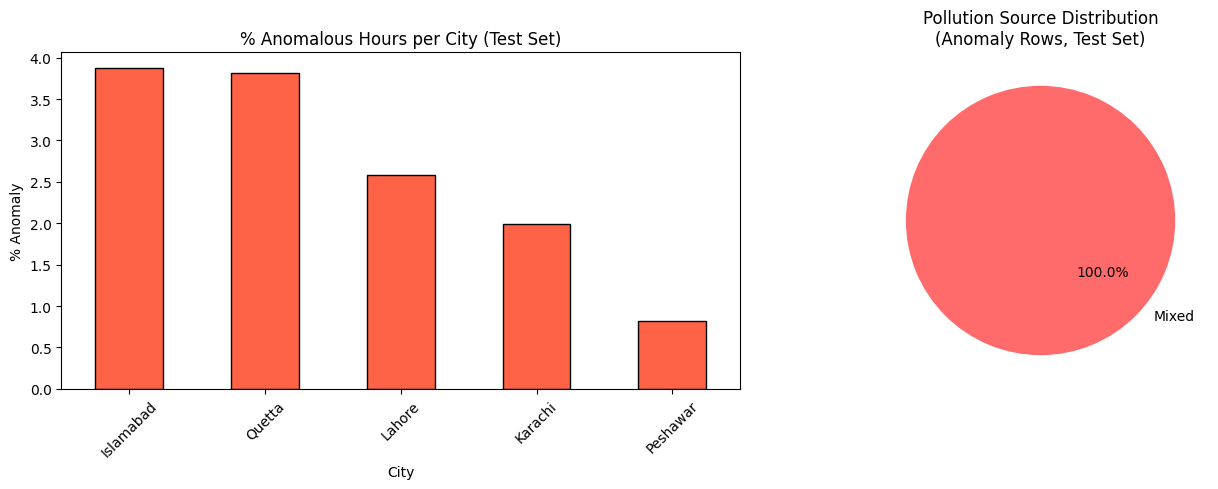

✅ Saved: anomaly_distribution.png


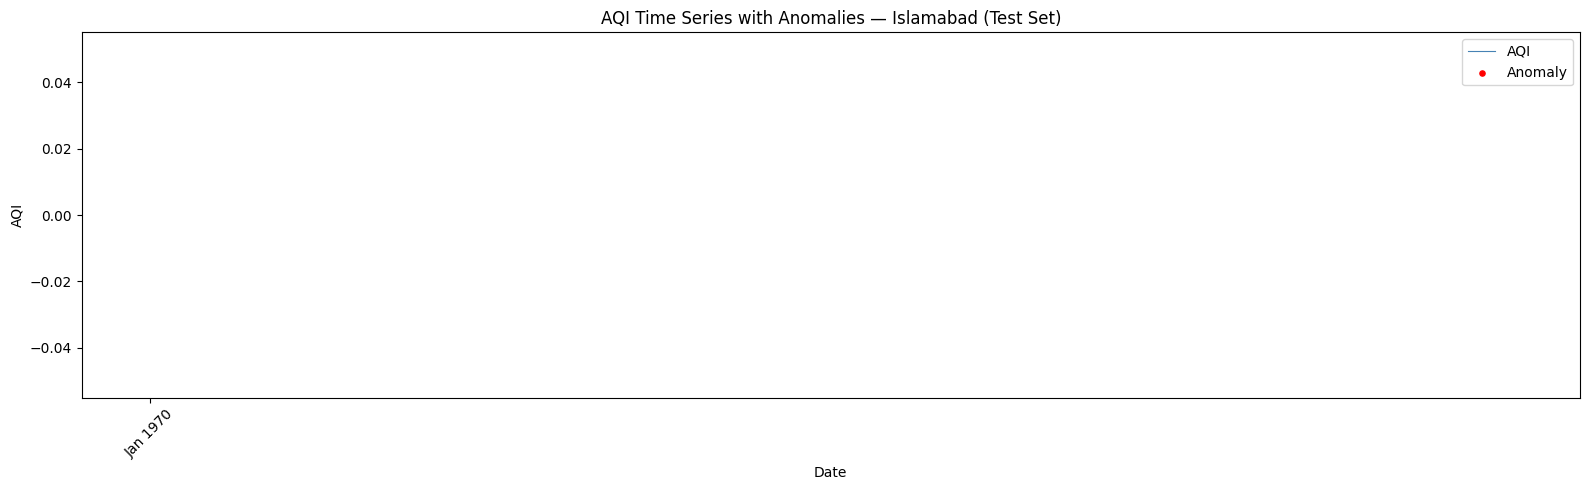

✅ Saved: aqi_timeseries_islamabad.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. % anomalies per city
city_anom = test_feat.groupby("city")["anomaly_flag"].mean() * 100
city_anom.sort_values(ascending=False).plot(
    kind="bar", ax=axes[0], color="tomato", edgecolor="black")
axes[0].set_title("% Anomalous Hours per City (Test Set)", fontsize=12)
axes[0].set_xlabel("City")
axes[0].set_ylabel("% Anomaly")
axes[0].tick_params(axis="x", rotation=45)

# 2. Source label distribution
if "source_label" in test_feat.columns:
    src_dist = test_feat[test_feat["anomaly_flag"]==1]["source_label"].value_counts()
    if len(src_dist):
        src_dist.plot(
            kind="pie", ax=axes[1], autopct="%1.1f%%",
            colors=["#FF6B6B","#4ECDC4","#45B7D1","#FFA07A","#98D8C8"],
            startangle=140)
        axes[1].set_title("Pollution Source Distribution\n(Anomaly Rows, Test Set)", fontsize=12)
        axes[1].set_ylabel("")

plt.tight_layout()
fig_path = str(OUTPUT_DIR / "anomaly_distribution.png")
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"✅ Saved: {fig_path}")

# 3. AQI time-series with anomaly overlay (most data-rich city)
city_plot = test_feat["city"].value_counts().index[0]
city_df   = test_feat[test_feat["city"] == city_plot].sort_values("datetime")

if "aqi" in city_df.columns:
    fig2, ax2 = plt.subplots(figsize=(16, 5))
    ax2.plot(city_df["datetime"], city_df["aqi"], lw=0.8,
             color="steelblue", label="AQI")
    anom_rows = city_df[city_df["anomaly_flag"] == 1]
    ax2.scatter(anom_rows["datetime"], anom_rows["aqi"],
                color="red", s=14, zorder=5, label="Anomaly")
    ax2.set_title(f"AQI Time Series with Anomalies — {city_plot} (Test Set)", fontsize=12)
    ax2.set_xlabel("Date")
    ax2.set_ylabel("AQI")
    ax2.xaxis.set_major_locator(mdates.MonthLocator())
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    plt.xticks(rotation=45)
    ax2.legend()
    plt.tight_layout()
    ts_path = str(OUTPUT_DIR / f"aqi_timeseries_{city_plot.lower()}.png")
    plt.savefig(ts_path, dpi=120, bbox_inches="tight")
    plt.show()
    print(f"✅ Saved: {ts_path}")

## 🔔 Cell 11 — Alert Generation

In [11]:
def _aqi_severity(aqi_val):
    if pd.isna(aqi_val):  return "Unknown"
    if aqi_val <= 50:     return "Good"
    if aqi_val <= 100:    return "Moderate"
    if aqi_val <= 150:    return "Unhealthy for Sensitive"
    if aqi_val <= 200:    return "Unhealthy"
    if aqi_val <= 300:    return "Very Unhealthy"
    return "Hazardous"


anom_df = test_feat[test_feat["anomaly_flag"] == 1].copy()

aqi_col = "aqi" if "aqi" in anom_df.columns else None

alerts_df = pd.DataFrame({
    "datetime":      anom_df["datetime"].values,
    "city":          anom_df["city"].values,
    "anomaly_score": anom_df["anomaly_score"].round(4).values,
    "source_label":  anom_df["source_label"].values,
    "source_prob":   anom_df["source_prob"].values if "source_prob" in anom_df.columns else np.nan,
    "aqi":           anom_df[aqi_col].values if aqi_col else np.nan,
    "severity":      anom_df[aqi_col].apply(_aqi_severity).values if aqi_col else "Unknown",
}).sort_values("anomaly_score", ascending=False).reset_index(drop=True)

print(f"  Total alerts generated : {len(alerts_df):,}")
print("\n  Top 10 alerts:")
display(alerts_df.head(10))

  Total alerts generated : 223

  Top 10 alerts:


,datetime,city,anomaly_score,source_label,source_prob,aqi,severity
0,2024-06-09 19:00:00,Islamabad,0.0392,Mixed,1.0,NaN,Unknown
1,2024-06-09 21:00:00,Islamabad,0.0309,Mixed,1.0,NaN,Unknown
2,2024-04-11 16:00:00,Lahore,0.0260,Mixed,1.0,NaN,Unknown
3,2024-05-12 06:00:00,Karachi,0.0248,Mixed,1.0,NaN,Unknown
4,2024-06-11 17:00:00,Lahore,0.0244,Mixed,1.0,NaN,Unknown
5,2024-06-11 16:00:00,Lahore,0.0230,Mixed,1.0,NaN,Unknown
6,2024-06-09 18:00:00,Islamabad,0.0226,Mixed,1.0,NaN,Unknown
7,2024-04-11 15:00:00,Lahore,0.0223,Mixed,1.0,NaN,Unknown
8,2024-06-09 20:00:00,Islamabad,0.0221,Mixed,1.0,NaN,Unknown
9,2024-10-12 17:00:00,Karachi,0.0218,Mixed,1.0,NaN,Unknown


## 💾 Cell 12 — Save Outputs

In [12]:
# ── Final predictions CSV ──────────────────────────────────────────────────
output_cols = [c for c in
               ["datetime","city","aqi","anomaly_flag","anomaly_score",
                "source_label","source_prob","season"]
               if c in test_feat.columns]

pred_path   = str(OUTPUT_DIR / "smognet_test_predictions.csv")
alerts_path = str(OUTPUT_DIR / "smognet_alerts.csv")
iso_path    = str(OUTPUT_DIR / "anomaly_model.pkl")
clf_path    = str(OUTPUT_DIR / "classifier_model.pkl")
pre_path    = str(OUTPUT_DIR / "preprocessor.pkl")

test_feat[output_cols].to_csv(pred_path,   index=False)
alerts_df.to_csv(alerts_path, index=False)
print(f"✅ Predictions : {pred_path}  ({len(test_feat):,} rows)")
print(f"✅ Alerts      : {alerts_path}  ({len(alerts_df):,} rows)")

# ── Save models ────────────────────────────────────────────────────────────
with open(iso_path, "wb") as f: pickle.dump(iso_forest, f)
with open(clf_path, "wb") as f: pickle.dump(clf_model,  f)
with open(pre_path, "wb") as f:
    pickle.dump({"imputer": imputer, "scaler": scaler,
                 "feature_cols": FEATURE_COLS,
                 "clf_feature_cols": clf_feature_cols,
                 "label_encoder": le}, f)

print(f"✅ Models saved : {iso_path}, {clf_path}, {pre_path}")

print("\n" + "="*60)
print("  🎉 SmogNet pipeline completed successfully!")
print("="*60)

✅ Predictions : smognet_test_predictions.csv  (8,520 rows)
✅ Alerts      : smognet_alerts.csv  (223 rows)
✅ Models saved : anomaly_model.pkl, classifier_model.pkl, preprocessor.pkl

  🎉 SmogNet pipeline completed successfully!
